Tugas Praktikum 1 - SVM pada data voice.csv (gender: male/female).

Kombinasi 2 rasio split (70:30, 80:20) x 3 kernel (linear, polynomial, RBF),
lalu tabulasi akurasi. Fitur distandarisasi (StandardScaler) karena SVM
sangat sensitif skala -- ini tambahan di luar jobsheet, dicatat di README.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("svm_voice.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js11-klasifikasi-2\tugas


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

BASE = Path(__file__).resolve().parent.parent
OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)

df = pd.read_csv(BASE / "data" / "voice.csv")
print(f"[data] voice.csv shape={df.shape}, kolom target='label'")
print(f"[data] distribusi label: {df.label.value_counts().to_dict()}")

X = df.drop(columns="label").values
y = (df.label == "male").astype(int).values  # male=1, female=0

KERNELS = {
    "linear": dict(kernel="linear", C=1.0),
    "poly": dict(kernel="poly", degree=3, C=1.0, gamma="scale"),
    "rbf": dict(kernel="rbf", C=10.0, gamma="scale"),
}
SPLITS = {"70:30": 0.30, "80:20": 0.20}

rows = []
for split_name, test_size in SPLITS.items():
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y)
    print(f"\n[split {split_name}] train={len(Xtr)} test={len(Xte)}")
    for kname, params in KERNELS.items():
        model = make_pipeline(StandardScaler(), SVC(**params))
        model.fit(Xtr, ytr)
        acc_tr = accuracy_score(ytr, model.predict(Xtr))
        ypred = model.predict(Xte)
        acc = accuracy_score(yte, ypred)
        f1 = f1_score(yte, ypred)
        rows.append(dict(split=split_name, kernel=kname, acc_train=acc_tr,
                         acc_test=acc, f1_test=f1))
        print(f"  kernel={kname:<6} acc_train={acc_tr:.4f} acc_test={acc:.4f} f1={f1:.4f}")

res = pd.DataFrame(rows)
piv = res.pivot(index="kernel", columns="split", values="acc_test")
print("\n=== TABEL AKURASI TEST (baris=kernel, kolom=split) ===")
print(piv.round(4).to_string())
print("\n=== TABEL AKURASI TRAIN ===")
print(res.pivot(index="kernel", columns="split", values="acc_train").round(4).to_string())
res.to_csv(OUT / "tabel_performa_voice.csv", index=False)

best = res.loc[res.acc_test.idxmax()]
print(f"\n[terbaik] split={best.split}, kernel={best.kernel}, acc_test={best.acc_test:.4f}")

[data] voice.csv shape=(3168, 21), kolom target='label'
[data] distribusi label: {'male': 1584, 'female': 1584}

[split 70:30] train=2217 test=951
  kernel=linear acc_train=0.9720 acc_test=0.9790 f1=0.9791
  kernel=poly   acc_train=0.9666 acc_test=0.9600 f1=0.9611


  kernel=rbf    acc_train=0.9937 acc_test=0.9821 f1=0.9821

[split 80:20] train=2534 test=634
  kernel=linear acc_train=0.9767 acc_test=0.9748 f1=0.9750
  kernel=poly   acc_train=0.9680 acc_test=0.9558 f1=0.9573


  kernel=rbf    acc_train=0.9941 acc_test=0.9890 f1=0.9889

=== TABEL AKURASI TEST (baris=kernel, kolom=split) ===
split    70:30   80:20
kernel                
linear  0.9790  0.9748
poly    0.9600  0.9558
rbf     0.9821  0.9890

=== TABEL AKURASI TRAIN ===
split    70:30   80:20
kernel                
linear  0.9720  0.9767
poly    0.9666  0.9680
rbf     0.9937  0.9941

[terbaik] split=80:20, kernel=rbf, acc_test=0.9890



=== classification_report model terbaik ===
              precision    recall  f1-score   support

      female     0.9844    0.9937    0.9890       317
        male     0.9936    0.9842    0.9889       317

    accuracy                         0.9890       634
   macro avg     0.9890    0.9890    0.9890       634
weighted avg     0.9890    0.9890    0.9890       634



[selesai] tugas 1


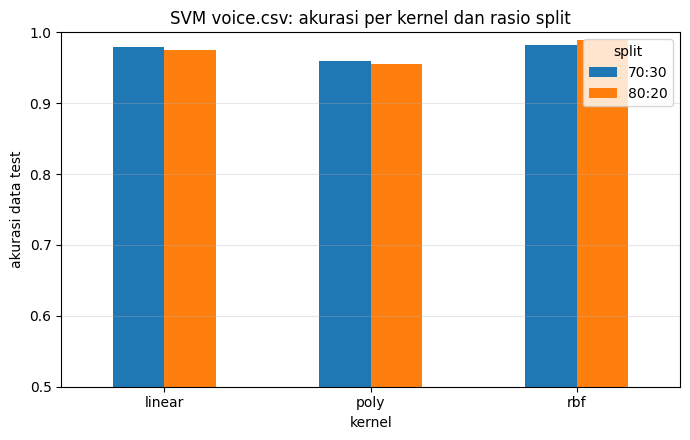

In [3]:
# classification report model terbaik
te = SPLITS[best.split]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=te, random_state=42, stratify=y)
model = make_pipeline(StandardScaler(), SVC(**KERNELS[best.kernel])).fit(Xtr, ytr)
print("\n=== classification_report model terbaik ===")
print(classification_report(yte, model.predict(Xte), target_names=["female", "male"], digits=4))

fig, ax = plt.subplots(figsize=(7, 4.5))
piv.plot(kind="bar", ax=ax, rot=0)
ax.set(ylabel="akurasi data test", xlabel="kernel", ylim=(0.5, 1.0),
       title="SVM voice.csv: akurasi per kernel dan rasio split")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "01_akurasi_voice.png", dpi=110)
print("[selesai] tugas 1")